## 1. Титульный лист
# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** Online Shoppers Purchasing Intention  
**Выполнил:** Боттер Вадим Валерьевич  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  
**Учебный год:** 2026/2027  
**Дата:** 02.11.2026  
**Репозиторий:** https://github.com/uat0/ml-course-botter  
**Ноутбук:** `module-4-features/notebook.ipynb`

Работа содержит воспроизводимый эксперимент, сохранённые результаты выполнения,
четыре базовые модели, подбор гиперпараметров и объяснения SHAP.

## 2. Введение

Задача — по характеристикам сессии интернет-магазина определить, завершилась ли она покупкой
(`Revenue=1`). Это бинарная классификация. Инженерия признаков переводит исходные наблюдения
в представление, в котором алгоритму проще найти полезные закономерности. Например, число
страниц и время просмотра вместе позволяют оценить глубину и интенсивность взаимодействия.

Для IT-компании прогноз полезен при ранжировании аудитории, анализе воронки и планировании
маркетинговых экспериментов. Применение в реальном времени требует отдельно подтвердить,
что все признаки доступны **до** принятия решения: агрегаты завершённой сессии сами по себе
этого не гарантируют.

Цели: создать не менее пяти новых признаков; обучить Random Forest, XGBoost, LightGBM и
CatBoost; сравнить модели и объяснить выбранную модель через SHAP. Дополнительно проверить
вклад инженерии признаков сравнением на одинаковых фолдах и чувствительность к PageValues.

Основная метрика выбора — ROC-AUC на стратифицированной кросс-валидации обучающей выборки.
Она оценивает ранжирование при разных порогах. Accuracy недостаточно: постоянный ответ
«покупки нет» уже даёт около 84.5%. F1, Precision, Recall и PR-AUC дополняют ROC-AUC и
показывают качество положительного класса; порог 0.5 зафиксирован заранее.

## 3. Теоретическая часть

**Feature Engineering.** Это создание, преобразование и отбор признаков для решения задачи.
Суммарное время сессии объединяет три вида активности. Доли позволяют сравнивать короткие
и длинные сессии. Новые признаки должны опираться на доступные исходные данные, а не на
целевую переменную. Их полезность проверяют экспериментом, поскольку увеличение числа
столбцов не гарантирует роста качества.

**Категориальные признаки.** Категория обозначает группу, а не величину. Label Encoding
присваивает метки, но при обычном числовом использовании создаёт искусственный порядок.
One-Hot Encoding выделяет каждой категории отдельный бинарный столбец. Здесь коды ОС,
браузера, региона и источника трафика также кодируются One-Hot; новые категории при
прогнозировании обрабатываются через `handle_unknown='ignore'`.

**Временные признаки.** Месяц отражает сезонность, а выходной — особенности посещения.
Для месяца полезно циклическое представление: $s_m=\sin(2\pi m/12)$,
$c_m=\cos(2\pi m/12)$, в котором декабрь соседствует с январём. Полной даты в наборе нет,
поэтому восстановить день недели или хронологический порядок нельзя. `SpecialDay`
описывает близость к специальному дню, а не точную дату.

**Поведенческие признаки.** Сумма страниц описывает глубину сессии. Сумма длительностей
приближённо отражает вовлечённость, но долгое время также может означать затруднение.
Средняя длительность на страницу нормирует время относительно объёма просмотра.
Доля товарных страниц описывает направленность интереса. При делении необходимо явно
определить поведение для нуля; сглаживание знаменателя меняет смысл показателя и фиксируется
в формуле.

**Дисбаланс классов.** Покупок значительно меньше, чем отказов от покупки. Модель может
получать высокую Accuracy, почти игнорируя покупателей. Веса классов повышают штраф за
ошибки положительного класса, но могут ухудшить калибровку вероятностей. SMOTE создаёт
синтетические примеры только внутри обучающих фолдов; обычный SMOTE для One-Hot категорий
может породить несуществующие комбинации, поэтому здесь используются веса классов.

**SHAP.** Значения Шепли распределяют отклонение ответа модели от базового значения между
признаками. Summary показывает общую картину вкладов и значений признаков. Bar ранжирует
средний абсолютный вклад, waterfall объясняет одну сессию, dependence показывает изменение
вклада относительно значения признака. Для бустинга в режиме `raw` вклады выражены в
логарифме шансов, а не в процентных пунктах вероятности. Коррелирующие производные могут
делить важность между собой; объяснение модели не доказывает причинное влияние.

**Bagging и boosting.** В bagging усредняют независимо обученные деревья:
$$\hat p(x)=\frac1B\sum_{b=1}^B \hat p_b(x).$$
В boosting деревья последовательно корректируют текущую функцию:
$$F_t(x)=F_{t-1}(x)+\eta h_t(x),\qquad p(x)=\sigma(F_T(x)).$$
Деревья бустинга приближают отрицательный градиент функции потерь; регуляризация ограничивает
сложность ансамбля. Подробнее: [scikit-learn](https://scikit-learn.org/stable/modules/ensemble.html),
[XGBoost](https://arxiv.org/abs/1603.02754).

| Модель | Подход | Особенность | Ограничение |
|---|---|---|---|
| Random Forest | Bagging | Случайные подвыборки объектов и признаков | Большой ансамбль занимает память |
| XGBoost | Boosting | Регуляризация и гистограммные разбиения | Нужен подбор сложности |
| LightGBM | Boosting | Гистограммы и рост дерева по листьям | Много листьев усиливает переобучение |
| CatBoost | Boosting | Специальная обработка категорий и ordered boosting | Здесь используется общее One-Hot представление |

Одинаковое кодирование обеспечивает сопоставимый эксперимент; отдельный эксперимент с
нативными категориями CatBoost мог бы дать другой результат.

**Другие методы модуля.** TF-IDF взвешивает слова по частоте в документе и редкости в корпусе:
$\mathrm{tfidf}(t,d)=\mathrm{tf}(t,d)\log(N/\mathrm{df}(t))$ (одна из конвенций).
Формула Haversine вычисляет расстояние по широте и долготе:
$d=2R\arcsin\sqrt{\sin^2(\Delta\varphi/2)+\cos\varphi_1\cos\varphi_2\sin^2(\Delta\lambda/2)}$.
DBSCAN находит плотные группы по `eps` и `min_samples`, выделяя шум. Лаг $x_{t-k}$ и среднее
по окну $k^{-1}\sum_{j=1}^k x_{t-j}$ используют только прошлые значения. В текущем наборе
нет текстов, координат или упорядоченных событий одного пользователя, поэтому эти методы
не применяются искусственно.

## 4. Описание данных

Источник: [UCI, датасет №468](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset).
Авторы: C. Sakar, Y. Kastro (2018), DOI: [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q).
Лицензия CC BY 4.0. Исходный CSV сохранён без изменения.

Одна строка — сессия; UCI указывает, что сессии относятся к разным пользователям в течение
одного года. 12 330 строк, 17 входных признаков и целевая `Revenue`. Из 17 входов 10
числовых и 7 категориальных, включая месяц и выходной. Классы: 10 422 без покупки и 1 908
с покупкой. Числовые идентификаторы категорий не интерпретируются как упорядоченные величины.

In [1]:
# Импорты и фиксированные настройки обеспечивают воспроизводимость запуска.
# JSON хранит метаданные, hashlib контролирует целостность файлов.
import json, hashlib, platform, time, warnings, sys
# Path обеспечивает переносимые относительные пути.
from pathlib import Path
import importlib.metadata as metadata
# NumPy используется для векторных формул и проверок равенства.
import numpy as np
# Pandas сохраняет имена и типы табличных признаков.
import pandas as pd
import matplotlib
# Статический backend позволяет запускать полный код без окна приложения.
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
# Неиспользуемый виджет прогресса не влияет на расчёты.
warnings.filterwarnings('ignore', message='IProgress not found.*')
import joblib, optuna, shap, requests
# Таблицы и рисунки сохраняются в выводах ноутбука.
from IPython.display import display, Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
# clone создаёт необученную модель с теми же параметрами.
from sklearn.base import clone
# ColumnTransformer разделяет обработку чисел и категорий.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Imputer обучает статистики заполнения только на train.
from sklearn.impute import SimpleImputer
# Стратификация сохраняет долю покупок в разбиениях.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay)
# Отдельные реализации бустинга сравниваются на одинаковых данных.
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Все пути считаются от папки модуля; обучение ограничено четырьмя потоками.
# Seed фиксирует случайность, THREADS ограничивает загрузку процессора.
SEED, THREADS, N_TRIALS = 42, 4, 30
ROOT = Path('.') if Path('data').exists() else Path('module-4-features')
for folder in ['models', 'examples']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
# Единые подписи и стиль упрощают сопоставление графиков.
sns.set_theme(style='whitegrid', font='DejaVu Sans', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False,
                     'axes.spines.right': False})

# Сохраняем график и выводим его в ноутбуке, не оставляя открытые фигуры.
def finish_plot(name):
    # Изображение доступно отдельно от ноутбука для приложения к отчёту.
    plt.savefig(ROOT / 'examples' / name, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close('all')

# Загружаем именно сохранённую копию данных и проверяем её размер и контрольную сумму.
data_path = ROOT / 'data/online_shoppers_intention.csv'
df = pd.read_csv(data_path)
dataset_sha = hashlib.sha256(data_path.read_bytes()).hexdigest()
# Размер проверяется до анализа, чтобы не обучиться на другом файле.
assert df.shape == (12330, 18)
assert dataset_sha == 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9'
print('Размер:', df.shape)
print(df.head().to_string(index=False))
print('SHA-256:', dataset_sha)
display(df.dtypes.rename('Тип').to_frame())

# Сравниваем число и долю классов в исходном файле.
# Положительный класс нельзя оценивать одной Accuracy.
class_counts = df['Revenue'].value_counts().sort_index()
display(pd.DataFrame({'Количество': class_counts, 'Доля': class_counts / len(df)}))

Размер: (12330, 18)
 Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  Browser  Region  TrafficType       VisitorType  Weekend  Revenue
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 1        1       1            1 Returning_Visitor    False    False
              0                      0.0              0                     0.0               2                64.000000         0.00       0.10         0.0         0.0   Feb                 2        2       1            2 Returning_Visitor    False    False
              0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 4        1  

,Тип
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


,Количество,Доля
Revenue,,
False,10422,0.845255
True,1908,0.154745


| Столбцы | Смысл | Тип |
|---|---|---|
| Administrative, Informational, ProductRelated | Число страниц соответствующего вида | Числовой |
| Administrative_Duration, Informational_Duration, ProductRelated_Duration | Время по видам страниц, секунды | Числовой |
| BounceRates, ExitRates | Метрики отказов и выходов | Числовой |
| PageValues | Средняя ценность посещённых страниц | Числовой |
| SpecialDay | Близость к особому дню | Числовой |
| Month | Месяц сессии | Категориальный |
| OperatingSystems, Browser, Region, TrafficType | Идентификаторы категорий | Категориальный |
| VisitorType | Новый, вернувшийся или другой посетитель | Категориальный |
| Weekend | Признак выходного | Категориальный, булев |
| Revenue | Совершена ли покупка | Целевой, булев |

В исходном наборе нет пропусков; это проверяется в следующем разделе.
Детальное описание и происхождение сохранены в `data/dataset_info.md`.

## 5. Подготовка данных и EDA

Сначала проверяются пропуски и дубли. Полные дубли удаляются перед разделением, чтобы
одинаковые записи не увеличивали оценку качества. Входы с одинаковыми значениями и разными
метками отдельно проверяются. Затем выполняется train/test = 80/20 с `stratify=y` и seed=42.
Графики зависимостей строятся на train; test сохраняется для контрольной оценки.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


Пропусков: 0
Полных дублей: 125
Значения Month: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


,Размер,Доля покупок
train,9764,0.156288
test,2441,0.156493


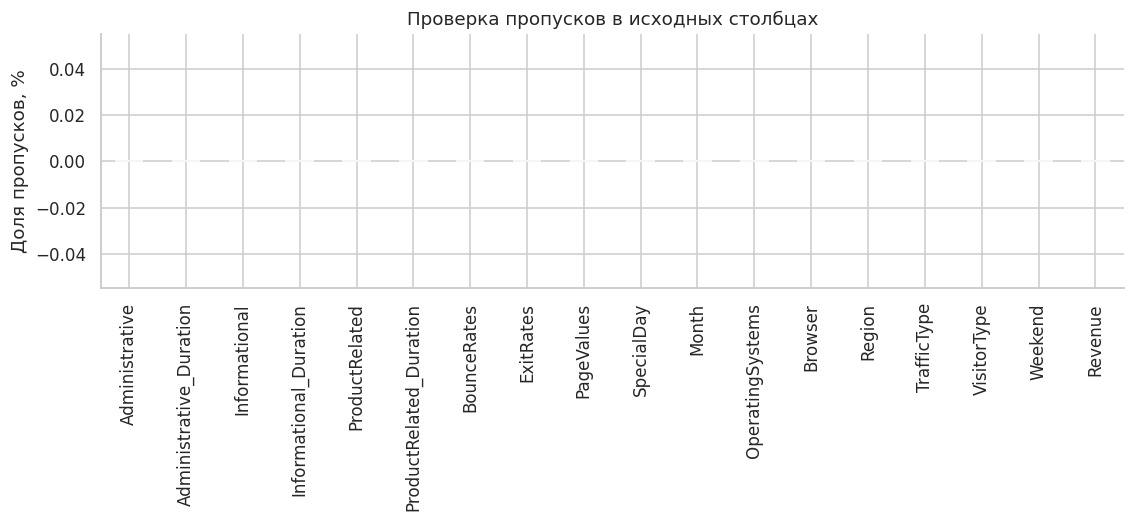

In [2]:
# Первичная диагностика не подменяется предположением об отсутствии ошибок.
df.info()
# Описательная статистика показывает диапазоны и редкие категории.
display(df.describe(include='all').T)
print('Пропусков:', int(df.isna().sum().sum()))
print('Полных дублей:', int(df.duplicated().sum()))
print('Значения Month:', sorted(df['Month'].unique()))

# Удаляем только точные дубли; проверяем отсутствие конфликтующих меток.
clean = df.drop_duplicates().copy()
# Целевая переменная исключается из проверки идентичности входов.
input_cols = df.columns.drop('Revenue').tolist()
# При конфликтующих метках обычного удаления дублей было бы недостаточно.
conflicts = clean.groupby(input_cols, dropna=False)['Revenue'].nunique().gt(1).sum()
assert conflicts == 0, 'Одинаковые входы с разными метками требуют группового разделения'
# Булева целевая переводится в числовые классы 0 и 1.
y = clean['Revenue'].astype(int)
X_raw = clean.drop(columns='Revenue')
# Индексы сохраняют связь с неизменённым исходным CSV.
train_idx, test_idx = train_test_split(clean.index, test_size=0.2, stratify=y,
                                      random_state=SEED)
# Пересечение train и test должно быть пустым.
assert set(train_idx).isdisjoint(test_idx)
eda = clean.loc[train_idx].copy()
# Проверяем размер и баланс классов после стратификации.
split_info = pd.DataFrame({'Размер': [len(train_idx), len(test_idx)],
    'Доля покупок': [y.loc[train_idx].mean(), y.loc[test_idx].mean()]}, index=['train', 'test'])
display(split_info)

# График пропусков использует исходный набор и показывает фактически нулевые значения.
plt.figure(figsize=(12, 3))
df.isna().mean().mul(100).plot.bar(color='#386cb0')
plt.ylabel('Доля пропусков, %')
plt.title('Проверка пропусков в исходных столбцах')
finish_plot('missing_values.png')

После удаления 125 дублей осталось **12,205** сессий.
Train: **9,764**, test: **2,441**; доли покупок —
15.63% и 15.65% соответственно. Пропусков и
конфликтующих меток у одинаковых входов не обнаружено. Января и апреля в исходном CSV нет;
это ограничивает выводы о полной годовой сезонности.

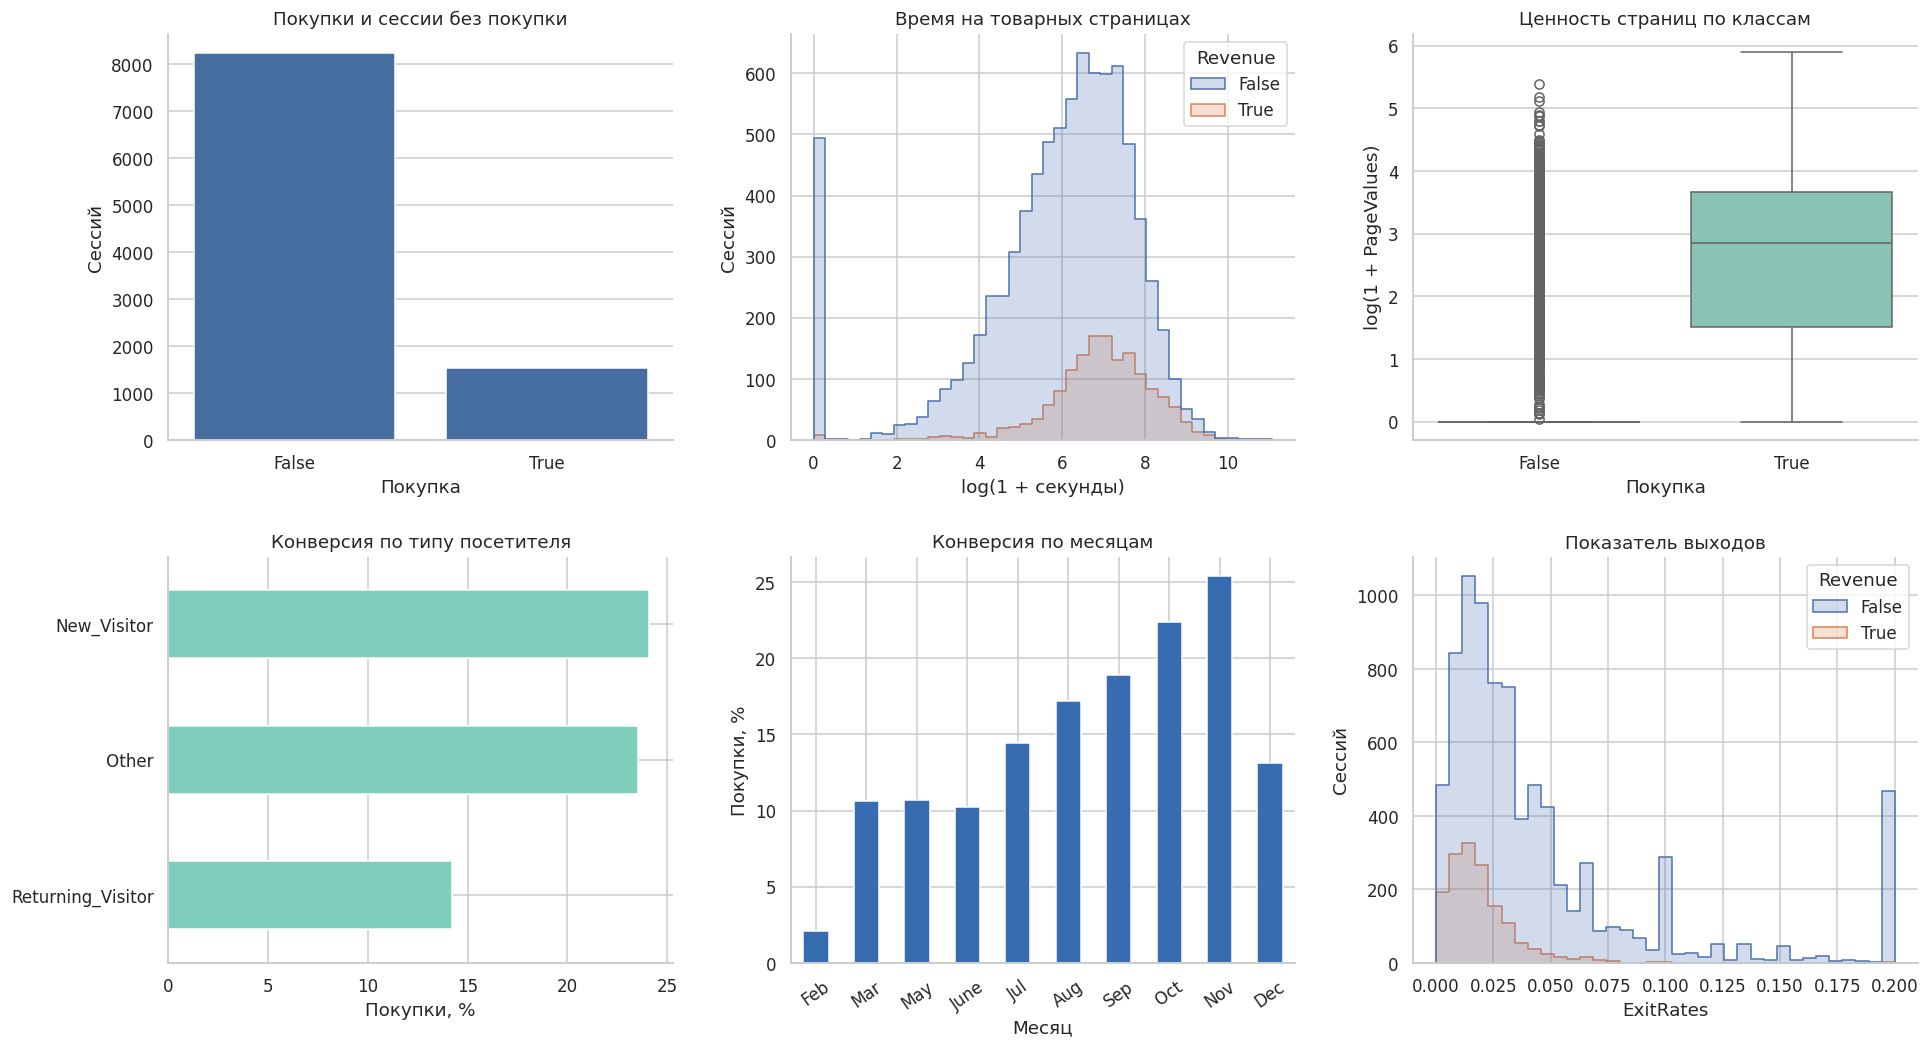

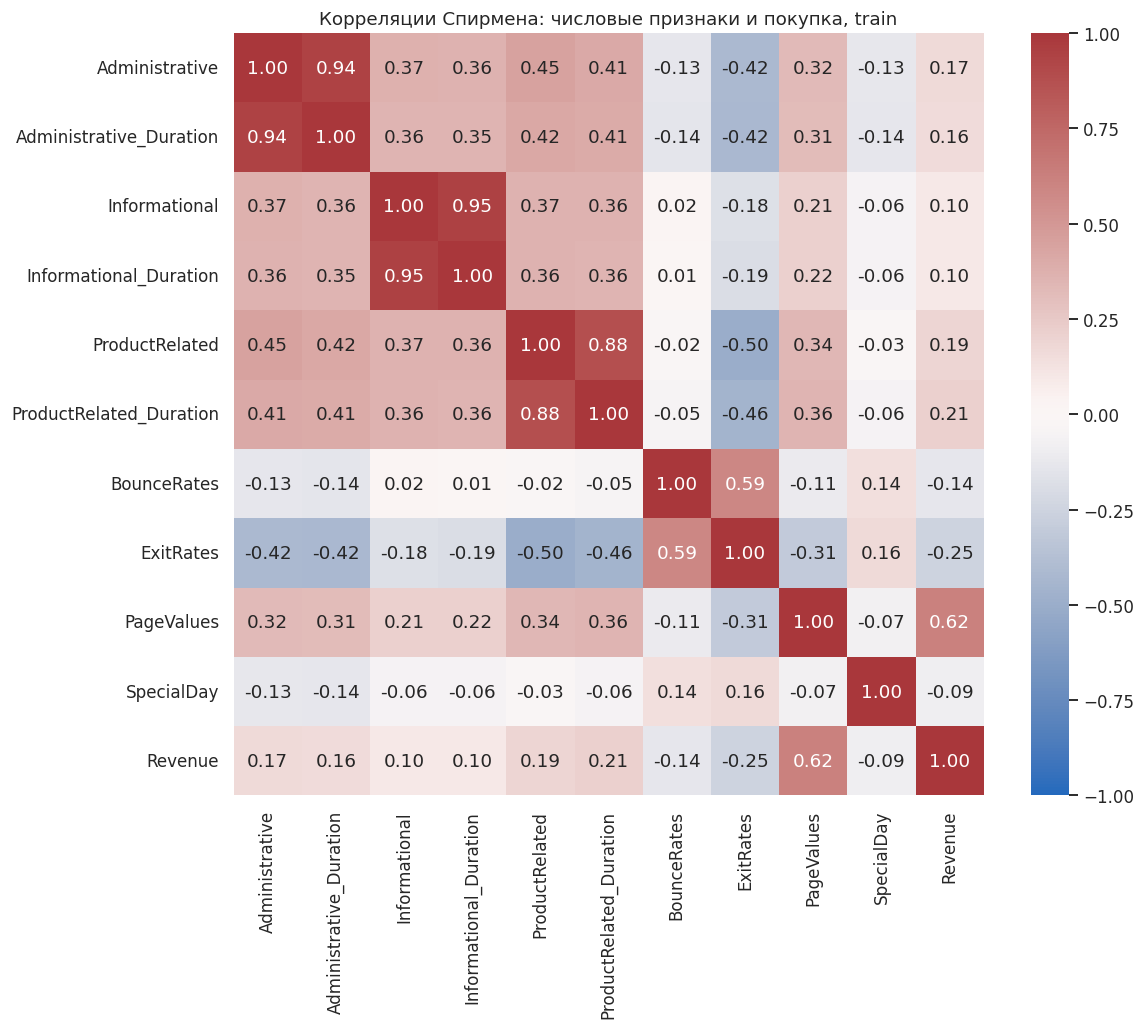

In [3]:
# Шесть графиков раскрывают дисбаланс, распределения и конверсию на train.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# Частоты показывают масштаб дисбаланса покупателей и остальных сессий.
sns.countplot(data=eda, x='Revenue', ax=axes[0, 0], color='#386cb0')
axes[0, 0].set(title='Покупки и сессии без покупки', xlabel='Покупка', ylabel='Сессий')
# Логарифм делает видимым распределение с длинным правым хвостом.
eda['LogProductDuration'] = np.log1p(eda['ProductRelated_Duration'])
# Разделение по Revenue показывает различие распределений классов.
sns.histplot(data=eda, x='LogProductDuration', hue='Revenue', bins=40,
             common_norm=False, element='step', ax=axes[0, 1])
axes[0, 1].set(title='Время на товарных страницах', xlabel='log(1 + секунды)', ylabel='Сессий')
# Нули сохраняются, поскольку используется log1p, а не log.
eda['LogPageValues'] = np.log1p(eda['PageValues'])
sns.boxplot(data=eda, x='Revenue', y='LogPageValues', ax=axes[0, 2], color='#7fcdbb')
axes[0, 2].set(title='Ценность страниц по классам', xlabel='Покупка', ylabel='log(1 + PageValues)')

# Для категорий показываем наблюдаемую долю покупок без причинной интерпретации.
# Доля покупок нормирует сравнение групп разного размера.
visitor_rates = eda.groupby('VisitorType')['Revenue'].mean().mul(100).sort_values()
visitor_rates.plot.barh(ax=axes[1, 0], color='#7fcdbb')
axes[1, 0].set(title='Конверсия по типу посетителя', xlabel='Покупки, %', ylabel='')
# Месяцы располагаются хронологически, а не по алфавиту.
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
eda.groupby('Month')['Revenue'].mean().reindex(month_order).mul(100).plot.bar(
    ax=axes[1, 1], color='#386cb0', rot=35)
axes[1, 1].set(title='Конверсия по месяцам', xlabel='Месяц', ylabel='Покупки, %')
sns.histplot(data=eda, x='ExitRates', hue='Revenue', bins=35, element='step',
             common_norm=False, ax=axes[1, 2])
axes[1, 2].set(title='Показатель выходов', xlabel='ExitRates', ylabel='Сессий')
fig.tight_layout(pad=2)
finish_plot('eda_plots.png')

# Корреляции рассчитываются только для количественных признаков, а не кодов категорий.
numeric_original = ['Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
plt.figure(figsize=(11, 9))
# Спирмен оценивает монотонные связи без требования нормальности.
sns.heatmap(eda[numeric_original + ['Revenue']].corr(method='spearman'),
            cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f')
plt.title('Корреляции Спирмена: числовые признаки и покупка, train')
finish_plot('correlation_heatmap.png')

На train конверсия новых посетителей равна **24.09%**,
вернувшихся — **14.20%**. Таким образом, в этих данных
новые посетители покупают чаще; противоположный тезис из примерного текста задания не
подтверждается. У группы Other всего 68 обучающих сессий,
поэтому её доля менее устойчива. Максимальная наблюдаемая месячная конверсия —
Nov (25.40%); различия могут зависеть от состава
трафика. Распределения времени имеют длинный правый хвост. PageValues у покупателей
обычно выше, но это также требует проверки происхождения признака.

Новые признаки рассчитываются независимо для каждой строки и не требуют обучения.

| Признак | Формула / правило | Обоснование |
|---|---|---|
| TotalPages | Administrative + Informational + ProductRelated | Глубина просмотра |
| TotalDuration | Сумма трёх длительностей | Общая продолжительность активности |
| AvgPageValue | PageValues / (TotalPages + 1) | Сглаженная нормировка ценности; не истинная средняя цена |
| BounceExitRatio | BounceRates / (ExitRates + 0.001) | Относительный уровень отказов и выходов |
| IsNewVisitor | VisitorType = New_Visitor | Явное выделение нового посетителя |
| IsWeekend | Weekend → 0/1 | Бинарное представление выходного |
| MonthNum | Явное соответствие строк месяца числам | Корректная обработка June |
| IsHighTraffic | TrafficType > 10 | Условная группа кодов из задания, **не объём трафика** |
| DurationPerPage | TotalDuration / (TotalPages + 1) | Интенсивность взаимодействия |
| ProductPageShare | ProductRelated / max(TotalPages, 1) | Доля товарных страниц |
| ProductTimeShare | ProductRelated_Duration / max(TotalDuration, 1) | Доля времени на товарах |
| LogTotalDuration | log(1 + TotalDuration) | Сжатие длинного хвоста |
| MonthSin, MonthCos | sin/cos(2π MonthNum/12) | Цикличность месяца |

Некоторые признаки дублируют или преобразуют исходную информацию. Это осознанный набор
кандидатов, а не доказательство их полезности. `TrafficType` — номинальный код: имя
`IsHighTraffic` сохранено по примеру задания, но не означает «много посетителей».

In [4]:
# Явная карта принимает также альтернативное английское сокращение Jun.
MONTH_MAP = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6,
             'Jun': 6, 'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}

def engineer_features(frame):
    # Копия предотвращает изменение исходных данных при повторном вызове.
    out = frame.drop(columns=['Revenue'], errors='ignore').copy()
    # Булев выходной получает однозначное числовое представление.
    out['Weekend'] = out['Weekend'].astype(int)
    out['TotalPages'] = out[['Administrative', 'Informational', 'ProductRelated']].sum(axis=1)
    out['TotalDuration'] = out[['Administrative_Duration', 'Informational_Duration',
                               'ProductRelated_Duration']].sum(axis=1)
    # Сглаживание знаменателя исключает деление на ноль.
    # Единица в знаменателе задаёт сглаживание, а не настоящую среднюю цену.
    out['AvgPageValue'] = out['PageValues'] / (out['TotalPages'] + 1)
    out['BounceExitRatio'] = out['BounceRates'] / (out['ExitRates'] + 0.001)
    # Значение определяется только типом текущего посетителя.
    out['IsNewVisitor'] = out['VisitorType'].eq('New_Visitor').astype(int)
    out['IsWeekend'] = out['Weekend']
    # Неизвестный месяц станет NaN и будет обработан обученным imputer.
    out['MonthNum'] = out['Month'].map(MONTH_MAP)
    # Условная группа номинальных кодов не измеряет интенсивность трафика.
    out['IsHighTraffic'] = out['TrafficType'].gt(10).astype(int)
    out['DurationPerPage'] = out['TotalDuration'] / (out['TotalPages'] + 1)
    # Доля товара отделяет профиль интереса от длины сессии.
    out['ProductPageShare'] = out['ProductRelated'] / out['TotalPages'].clip(lower=1)
    # Доля времени дополняет простое число товарных страниц.
    out['ProductTimeShare'] = out['ProductRelated_Duration'] / out['TotalDuration'].clip(lower=1)
    # Временные и логарифмические преобразования используют только значения текущей строки.
    out['LogTotalDuration'] = np.log1p(out['TotalDuration'])
    out['MonthSin'] = np.sin(2 * np.pi * out['MonthNum'] / 12)
    out['MonthCos'] = np.cos(2 * np.pi * out['MonthNum'] / 12)
    return out

# Медианы, категории и параметры масштаба будут оцениваться внутри каждого train-фолда.
CATEGORICAL = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
def make_preprocessor(frame):
    # Список категорий фиксируется предметным смыслом, а не dtype.
    cats = [c for c in CATEGORICAL if c in frame.columns]
    # Остальные столбцы обрабатываются как количественные признаки.
    nums = [c for c in frame.columns if c not in cats]
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler', StandardScaler())])
    # Неизвестная категория не должна останавливать прогнозирование.
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    # Выход DataFrame сохраняет имена для интерпретации и проверки схемы.
    return ColumnTransformer([('numeric', num_pipe, nums), ('categorical', cat_pipe, cats)],
        verbose_feature_names_out=False).set_output(transform='pandas')

# Масштабирование для деревьев необязательно, но включено единообразно и сохраняется в scaler.pkl.
X = engineer_features(X_raw)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
assert np.isfinite(X.select_dtypes('number').to_numpy()).all()
new_features = X.columns.difference(X_raw.columns).tolist()
print('Новых признаков:', len(new_features), new_features)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Новых признаков: 14 ['AvgPageValue', 'BounceExitRatio', 'DurationPerPage', 'IsHighTraffic', 'IsNewVisitor', 'IsWeekend', 'LogTotalDuration', 'MonthCos', 'MonthNum', 'MonthSin', 'ProductPageShare', 'ProductTimeShare', 'TotalDuration', 'TotalPages']
Train: (9764, 31) Test: (2441, 31)


Итого создано 14 новых столбцов. Все преобразования в функции детерминированы; сама функция
не обращается к `Revenue`. One-Hot, заполнение пропусков и StandardScaler входят в Pipeline,
поэтому информация из validation/test не используется при их обучении. Вспомогательные
столбцы для графиков не попадают в модель.

## 6. Построение и обучение моделей

Все четыре модели получают одни и те же признаки и разбиения. Для выбора семейства используется
средний ROC-AUC по 5 фолдам `StratifiedKFold(shuffle=True, random_state=42)` только на train.
Для RF/LightGBM используются сбалансированные веса, для XGBoost — отношение классов в train,
для CatBoost — `auto_class_weights='Balanced'`. Время обучения измеряется отдельно от CV.

RF служит bagging-базой; XGBoost проверяет регуляризованный бустинг; LightGBM — быстрый
гистограммный бустинг; CatBoost — ещё одну реализацию бустинга. Здесь CatBoost получает
One-Hot, поэтому его нативная обработка категорий не сравнивается.

In [5]:
# Базовые конфигурации фиксируются до просмотра результатов test.
# Вес положительного класса рассчитывается без доступа к test.
positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())
estimators = {
    # Ограничение глубины и доли признаков сдерживает сложность RF.
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, max_features=0.3,
        class_weight='balanced', random_state=SEED, n_jobs=THREADS),
    # Гистограммный метод ускоряет сравнение при фиксированном seed.
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=positive_weight,
        random_state=SEED, n_jobs=THREADS, eval_metric='logloss', tree_method='hist'),
    # Регуляризация и глубина ограничивают листовой рост дерева.
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7,
        learning_rate=0.05, class_weight='balanced', random_state=SEED,
        reg_alpha=0.001, reg_lambda=0.001, subsample_freq=1,
        n_jobs=THREADS, verbosity=-1),
    # Запись служебных файлов CatBoost отключена для чистоты каталога.
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
        auto_class_weights='Balanced', random_seed=SEED, thread_count=THREADS,
        verbose=False, allow_writing_files=False),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Все семейства используют одни и те же пять пар train/validation.
cv_splits = list(cv.split(X_train, y_train))
fitted, cv_scores, fit_times, cv_times = {}, {}, {}, {}

# Pipeline повторно обучает всю предобработку на каждом фолде, предотвращая утечку.
for name, estimator in estimators.items():
    pipeline = Pipeline([('preprocess', make_preprocessor(X_train)), ('model', clone(estimator))])
    start = time.perf_counter()
    # ROC-AUC рассчитывается независимо на validation каждого фолда.
    cv_scores[name] = cross_val_score(pipeline, X_train, y_train, cv=cv_splits,
                                      scoring='roc_auc', n_jobs=1)
    cv_times[name] = time.perf_counter() - start
    # Финальная базовая модель обучается на всём train, но не на test.
    start = time.perf_counter()
    fitted[name] = pipeline.fit(X_train, y_train)
    # Измерение fit не включает время кросс-валидации.
    fit_times[name] = time.perf_counter() - start
    print(f'{name}: CV AUC={cv_scores[name].mean():.5f}, fit={fit_times[name]:.2f} с', flush=True)

# Семейство для Optuna выбирается исключительно по обучающей кросс-валидации.
selected_family = max(cv_scores, key=lambda name: cv_scores[name].mean())
# Разброс фолдов помогает оценить устойчивость среднего результата.
cv_table = pd.DataFrame([{'Модель': name, 'CV ROC-AUC': scores.mean(),
    'CV std': scores.std(ddof=1), 'Fit, с': fit_times[name], 'CV, с': cv_times[name]}
    for name, scores in cv_scores.items()]).sort_values('CV ROC-AUC', ascending=False)
display(cv_table.round(5))
print('Семейство для тюнинга:', selected_family)

Random Forest: CV AUC=0.93275, fit=0.94 с


XGBoost: CV AUC=0.92478, fit=0.33 с


LightGBM: CV AUC=0.92762, fit=0.23 с


CatBoost: CV AUC=0.92757, fit=0.90 с


,Модель,CV ROC-AUC,CV std,"Fit, с","CV, с"
0,Random Forest,0.93275,0.00493,0.93606,4.21945
2,LightGBM,0.92762,0.00491,0.23461,1.06880
3,CatBoost,0.92757,0.00585,0.89544,3.92145
1,XGBoost,0.92478,0.00439,0.33364,1.70023


Семейство для тюнинга: Random Forest


| Модель | CV ROC-AUC | CV std | Обучение, с |
| --- | --- | --- | --- |
| Random Forest | 0.9327 | 0.0049 | 0.9361 |
| LightGBM | 0.9276 | 0.0049 | 0.2346 |
| CatBoost | 0.9276 | 0.0059 | 0.8954 |
| XGBoost | 0.9248 | 0.0044 | 0.3336 |

По заранее выбранной метрике семейство для Optuna — **Random Forest**, CV ROC-AUC
**0.93275**. Стандартное отклонение — разброс между пятью фолдами, а не доверительный
интервал. Самая быстрая базовая модель на этой машине — **LightGBM**;
это измерение одного запуска, а не универсальная характеристика скорости.

## 7. Оценка качества

Контрольный test не участвует в обучении, подборе параметров или выборе семейства. Таблица
ниже содержит метрики при пороге 0.5, ROC-AUC и дополнительную PR-AUC (`average_precision`).
Просмотр test не меняет заранее заданное правило выбора по CV. Взвешивание классов делает
числа `predict_proba` некалиброванными оценками; они прежде всего используются для ранжирования.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,"Fit, sec"
0,Random Forest,0.88529,0.60537,0.76702,0.67667,0.93084,0.71633,0.93606
1,XGBoost,0.88693,0.61674,0.73298,0.66986,0.92692,0.72893,0.33364
2,LightGBM,0.87014,0.55985,0.79581,0.65730,0.93055,0.73996,0.23461
3,CatBoost,0.87095,0.56124,0.80366,0.66093,0.93252,0.73980,0.89544


Accuracy постоянного прогноза 0: 0.8435067595247849


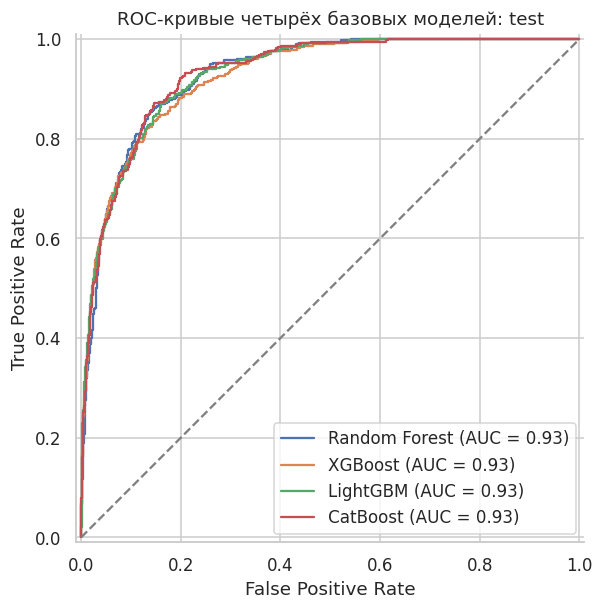

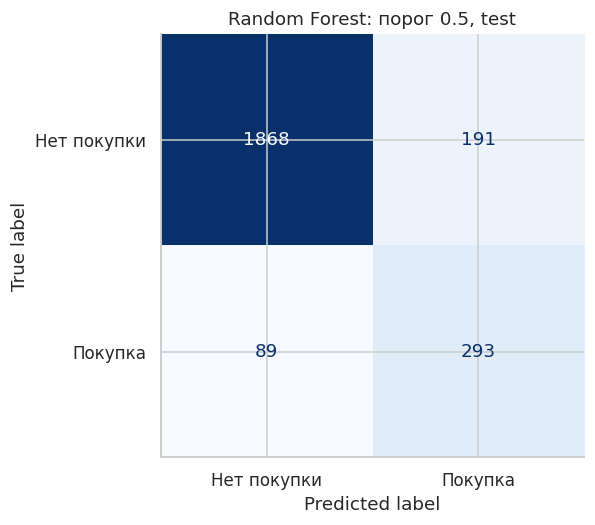

              precision    recall  f1-score   support

           0     0.9545    0.9072    0.9303      2059
           1     0.6054    0.7670    0.6767       382

    accuracy                         0.8853      2441
   macro avg     0.7799    0.8371    0.8035      2441
weighted avg     0.8999    0.8853    0.8906      2441



In [6]:
# Все метрики вычисляются по фактическим предсказаниям на одном и том же test.
def evaluate(model, frame, target, name):
    # Непороговые оценки нужны для ROC-AUC и PR-AUC.
    probability = model.predict_proba(frame)[:, 1]
    # Порог фиксирован до сравнения моделей и не выбирается на test.
    prediction = (probability >= 0.5).astype(int)
    # Precision и Recall относятся к положительному классу покупки.
    return {'Model': name, 'Accuracy': accuracy_score(target, prediction),
        'Precision': precision_score(target, prediction, zero_division=0),
        'Recall': recall_score(target, prediction), 'F1': f1_score(target, prediction),
        'ROC-AUC': roc_auc_score(target, probability),
        'PR-AUC': average_precision_score(target, probability)}

# Единая функция предотвращает различие методик расчёта между моделями.
results = [evaluate(model, X_test, y_test, name) for name, model in fitted.items()]
results_df = pd.DataFrame(results)
results_df['Fit, sec'] = results_df['Model'].map(fit_times)
display(results_df.round(5))
print('Accuracy постоянного прогноза 0:', accuracy_score(y_test, np.zeros(len(y_test))))

# ROC-кривые сравниваются на одной шкале с линией случайного ранжирования.
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in fitted.items():
    # Каждая кривая использует те же метки контрольной выборки.
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=name, ax=ax)
# Диагональ обозначает случайное ранжирование.
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(title='ROC-кривые четырёх базовых моделей: test', xlabel='False Positive Rate',
       ylabel='True Positive Rate')
finish_plot('roc_curves.png')

# Матрица показывается для модели, выбранной по CV, а не по test.
fig, ax = plt.subplots(figsize=(6, 5))
# Абсолютные количества ошибок дополняют усреднённые метрики.
ConfusionMatrixDisplay.from_predictions(y_test, fitted[selected_family].predict(X_test),
    display_labels=['Нет покупки', 'Покупка'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'{selected_family}: порог 0.5, test')
finish_plot('confusion_matrix_baseline.png')
print(classification_report(y_test, fitted[selected_family].predict(X_test), digits=4))

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
| --- | --- | --- | --- | --- | --- | --- |
| Random Forest | 0.8853 | 0.6054 | 0.7670 | 0.6767 | 0.9308 | 0.7163 |
| XGBoost | 0.8869 | 0.6167 | 0.7330 | 0.6699 | 0.9269 | 0.7289 |
| LightGBM | 0.8701 | 0.5599 | 0.7958 | 0.6573 | 0.9305 | 0.7400 |
| CatBoost | 0.8710 | 0.5612 | 0.8037 | 0.6609 | 0.9325 | 0.7398 |

На test максимальный ROC-AUC среди baseline получил **CatBoost**
(0.93252), но для тюнинга остаётся семейство **Random Forest**, выбранное
независимо по train-CV. Такое различие рейтингов ожидаемо при конечной выборке.
У Random Forest Recall=0.7670 и Precision=0.6054:
модель находит значительную часть покупок, но создаёт ложные положительные прогнозы.
При пороге 0.5 ошибки нужно оценивать с учётом цены маркетингового контакта.

## 8. Интерпретация и бизнес-инсайты

Встроенная важность показывает, какие закодированные признаки использует базовая модель,
выбранная по CV. Для RF это уменьшение impurity, для LightGBM — gain, для остальных —
соответствующая реализация importance. Числа между разными алгоритмами не сопоставляются.
Коррелирующие исходные и производные признаки могут делить важность.

Дополнительная проверка сравнивает на одинаковых train-фолдах: исходные 17 входов;
все исходные и новые признаки; полный набор без PageValues и его производного AvgPageValue.
Это сравнение с фиксированными параметрами одной модели, а не повторный поиск лучшей модели.

,Feature,Importance
13,AvgPageValue,0.297837
8,PageValues,0.258769
7,ExitRates,0.055155
5,ProductRelated_Duration,0.030221
23,MonthSin,0.028916
12,TotalDuration,0.026845
22,LogTotalDuration,0.025303
20,ProductPageShare,0.023696
17,MonthNum,0.023275
32,Month_Nov,0.019848


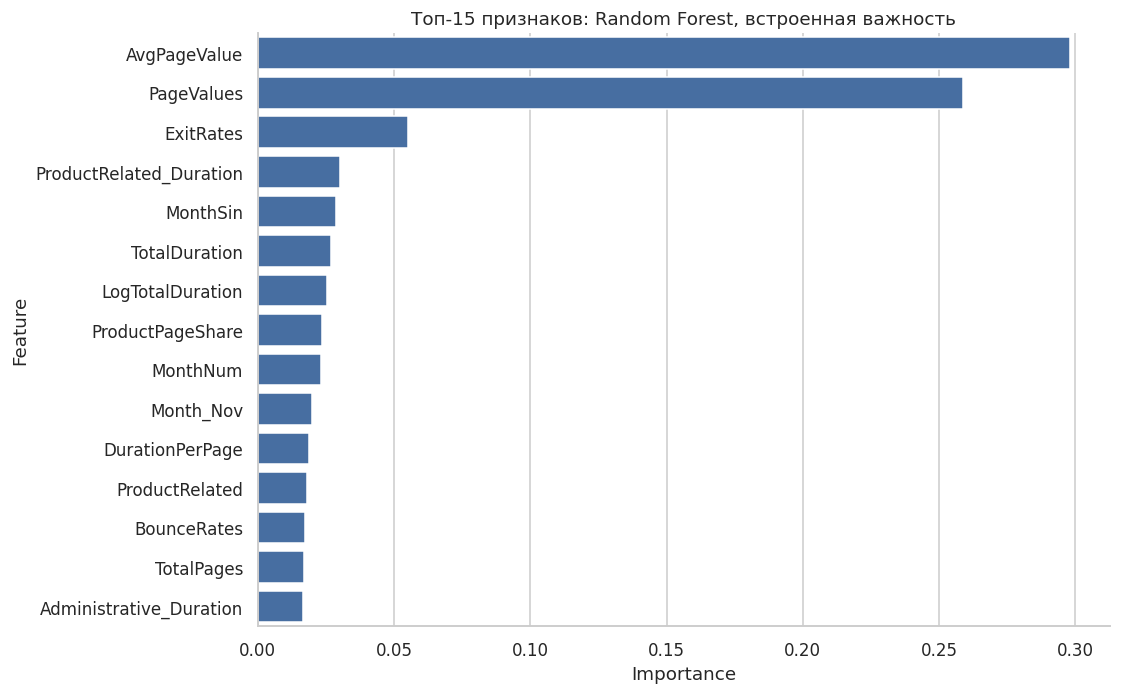

,Набор,CV ROC-AUC,CV std
0,Исходные признаки,0.93139,0.00425
1,С инженерией признаков,0.93275,0.00493
2,Без PageValues и AvgPageValue,0.77456,0.01380


In [7]:
# Получаем имена после One-Hot и важность выбранной базовой модели.
base_pipeline = fitted[selected_family]
# После One-Hot число столбцов отличается от числа исходных входов.
encoded_cols = base_pipeline.named_steps['preprocess'].get_feature_names_out().tolist()
tree = base_pipeline.named_steps['model']
# Для LightGBM явно выбирается gain; для RF — impurity importance.
importance_values = (tree.booster_.feature_importance(importance_type='gain')
                     if selected_family == 'LightGBM' else tree.feature_importances_)
# Каждое значение важности связывается с конкретным столбцом.
importances = pd.DataFrame({'Feature': encoded_cols, 'Importance': importance_values})
importances = importances.sort_values('Importance', ascending=False)
display(importances.head(15))
plt.figure(figsize=(10, 7))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', color='#386cb0')
plt.title(f'Топ-15 признаков: {selected_family}, встроенная важность')
finish_plot('feature_importance.png')

# Абляция использует только train и те же самые фолды, что и сравнение моделей.
# Исходное представление используется как контроль в абляции.
raw_train = X_raw.loc[train_idx].copy()
raw_train['Weekend'] = raw_train['Weekend'].astype(int)
# При удалении PageValues исключается также его производное.
ablation_frames = {'Исходные признаки': raw_train, 'С инженерией признаков': X_train,
    'Без PageValues и AvgPageValue': X_train.drop(columns=['PageValues', 'AvgPageValue'])}
ablation_scores = {}
for label, frame in ablation_frames.items():
    # Готовые CV-оценки полного набора повторно используются без лишнего обучения.
    if label == 'С инженерией признаков':
        ablation_scores[label] = cv_scores[selected_family]
    else:
        pipeline = Pipeline([('preprocess', make_preprocessor(frame)),
                              ('model', clone(estimators[selected_family]))])
        # Параметры модели и разбиения одинаковы для всех вариантов входа.
        ablation_scores[label] = cross_val_score(pipeline, frame, y_train, cv=cv_splits,
                                                 scoring='roc_auc', n_jobs=1)
ablation_table = pd.DataFrame([{'Набор': label, 'CV ROC-AUC': scores.mean(),
    'CV std': scores.std(ddof=1)} for label, scores in ablation_scores.items()])
display(ablation_table.round(5))
# Числовые результаты абляции доступны для независимого просмотра.
ablation_table.to_csv(ROOT / 'models/ablation.csv', index=False)

При фиксированных параметрах Random Forest новые признаки изменили CV ROC-AUC с
**0.93139** до
**0.93275**, разница **+0.00136**.
Она мала по сравнению с разбросом фолдов; статистически доказанного выигрыша на её основе
заявлять нельзя. Без PageValues и AvgPageValue ROC-AUC равен
**0.77456**. Это показывает сильную
зависимость результата от группы признаков ценности страницы и ограничивает переносимость
модели, если эти данные недоступны в момент принятия решения.

Практические гипотезы: сегментировать трафик по характеру просмотра, исследовать причины
выхода с товарных страниц, проверять сезонные кампании. Наблюдаемая связь не означает, что
искусственное увеличение времени или количества страниц повысит конверсию: это проверяется
A/B-тестом. У UCI `PageValues` связан с ценностью страниц перед транзакцией; происхождение
и момент расчёта этого признака требуют аудита перед использованием в онлайн-прогнозе.
Обучение на агрегатах завершённой сессии здесь рассматривается как учебная классификация.

## 9. Тюнинг гиперпараметров (Optuna)

Оптимизируется семейство с максимальным средним train-CV ROC-AUC. Используется TPE с
фиксированным seed, **30 испытаний по 5 фолдов**. Предобработка каждый раз обучается
внутри фолда. В поиск включена исходная конфигурация, поэтому лучший CV-результат поиска
не хуже исходной точки; это не гарантирует улучшения на test. Диапазон числа листьев для
LightGBM ограничивается глубиной дерева. При отсутствии выигрыша сохраняется baseline.

Trial 01/30: CV=0.93275, best=0.93275


Trial 02/30: CV=0.93246, best=0.93275


Trial 03/30: CV=0.93240, best=0.93275


Trial 04/30: CV=0.92880, best=0.93275


Trial 05/30: CV=0.93434, best=0.93434


Trial 06/30: CV=0.93310, best=0.93434


... (22 outputs left out)

Trial 29/30: CV=0.93438, best=0.93473


Trial 30/30: CV=0.93403, best=0.93473


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.88529,0.60537,0.76702,0.67667,0.93084,0.71633
1,Random Forest (Optuna),0.87710,0.57455,0.82723,0.67811,0.93490,0.74886


Лучшие параметры: {'n_estimators': 300, 'max_depth': 9, 'min_samples_leaf': 11, 'max_features': 0.3023848897385063}
Время поиска, с: 284.62


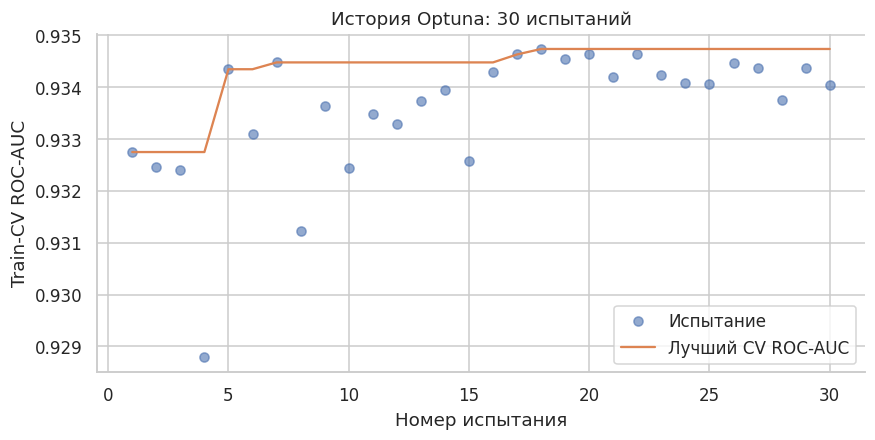

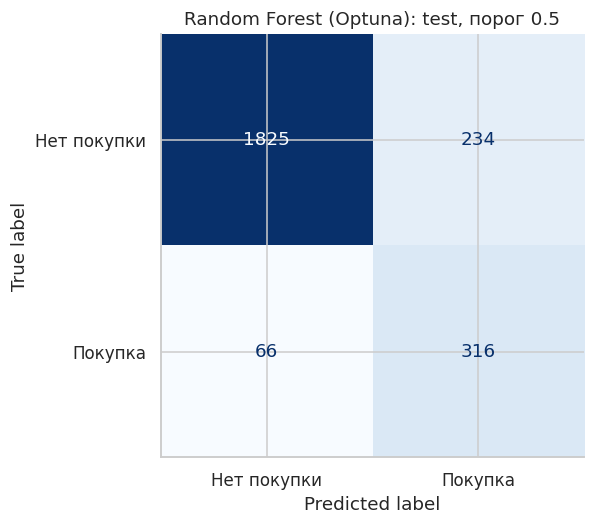

In [8]:
# Диапазоны ограничивают сложность и время поиска, не используя test.
# У каждого семейства своё пространство допустимых параметров.
def suggest_params(trial, family):
    if family == 'LightGBM':
        # Глубина определяет допустимое число листьев LightGBM.
        depth = trial.suggest_int('max_depth', 3, 9)
        # Число деревьев подбирается дискретно, чтобы ограничить время поиска.
        return {'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': depth, 'num_leaves': trial.suggest_int('num_leaves', 7, min(63, 2**depth)),
            # Логарифмическая шкала исследует как малые, так и большие шаги бустинга.
            'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.15, log=True),
            # Минимум объектов в листе ограничивает подгонку к редким сессиям.
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 80),
            # Подвыборка объектов может снижать корреляцию деревьев.
            'subsample': trial.suggest_float('subsample', 0.65, 1.0),
            # Подвыборка столбцов регулирует сложность бустинга.
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.65, 1.0),
            # L1-регуляризация исследуется в нескольких порядках величины.
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
            # L2-регуляризация штрафует слишком большие значения листьев.
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True)}
    if family == 'CatBoost':
        return {'iterations': trial.suggest_int('iterations', 100, 500, step=50),
            'depth': trial.suggest_int('depth', 3, 8),
            # Логарифмическая шкала исследует как малые, так и большие шаги бустинга.
            'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.15, log=True),
            # Регуляризация CatBoost включена в сравнение параметров.
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 20, log=True),
            # Случайность выбора разбиений выступает дополнительной регуляризацией.
            'random_strength': trial.suggest_float('random_strength', 0, 2)}
    if family == 'XGBoost':
        # Число деревьев подбирается дискретно, чтобы ограничить время поиска.
        return {'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 8),
            # Логарифмическая шкала исследует как малые, так и большие шаги бустинга.
            'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.15, log=True),
            # Подвыборка объектов может снижать корреляцию деревьев.
            'subsample': trial.suggest_float('subsample', 0.65, 1.0),
            # Подвыборка столбцов регулирует сложность бустинга.
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.65, 1.0),
            # Минимальный вес дочернего узла ограничивает сложность XGBoost.
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
            # L2-регуляризация штрафует слишком большие значения листьев.
            'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 20, log=True)}
    # Число деревьев подбирается дискретно, чтобы ограничить время поиска.
    return {'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'max_depth': trial.suggest_int('max_depth', 5, 18),
        # Число объектов в листе сглаживает прогнозы Random Forest.
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 12),
        'max_features': trial.suggest_float('max_features', 0.3, 1.0)}

# Первая точка совпадает с baseline; остальные ищутся алгоритмом TPE.
baseline_trial_params = {
    'LightGBM': dict(n_estimators=200, max_depth=7, num_leaves=31, learning_rate=0.05,
        min_child_samples=20, subsample=1.0, colsample_bytree=1.0, reg_alpha=0.001, reg_lambda=0.001),
    'CatBoost': dict(iterations=200, depth=6, learning_rate=0.1, l2_leaf_reg=3.0, random_strength=1.0),
    'XGBoost': dict(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,
        colsample_bytree=0.9, min_child_weight=1, reg_lambda=1.0),
    'Random Forest': dict(n_estimators=200, max_depth=10, min_samples_leaf=1, max_features=0.3)}

def objective(trial):
    # subsample_freq активирует подвыборки LightGBM; иначе subsample не используется.
    # Параметры trial передаются новому необученному экземпляру модели.
    params = suggest_params(trial, selected_family)
    model = clone(estimators[selected_family]).set_params(**params)
    if selected_family == 'LightGBM':
        model.set_params(subsample_freq=1)
    pipeline = Pipeline([('preprocess', make_preprocessor(X_train)), ('model', model)])
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv_splits,
                             scoring='roc_auc', n_jobs=1)
    # Отдельные оценки фолдов сохраняются вместе с результатом испытания.
    trial.set_user_attr('fold_scores', scores.tolist())
    return float(scores.mean())

# Логи сохраняют ход оптимизации; независимых test-оценок внутри objective нет.
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
# Исходная конфигурация включена в поиск как контрольная точка.
study.enqueue_trial(baseline_trial_params[selected_family])
start = time.perf_counter()
# Каждое из 30 испытаний оценивается на пяти train-фолдах.
study.optimize(objective, n_trials=N_TRIALS,
    callbacks=[lambda s, t: print(f'Trial {t.number+1:02d}/{N_TRIALS}: '
        f'CV={t.value:.5f}, best={s.best_value:.5f}', flush=True)])
tuning_seconds = time.perf_counter() - start

# Решение о сохранении baseline или tuned принимается до вычисления tuned test-метрик.
# Контрольная выборка не участвует в принятии решения о выборе tuned.
use_tuned = study.best_value > float(cv_scores[selected_family].mean())
best_params = study.best_params if use_tuned else {}
best_estimator = clone(estimators[selected_family]).set_params(**best_params)
if selected_family == 'LightGBM' and use_tuned:
    best_estimator.set_params(subsample_freq=1)
best_pipeline = Pipeline([('preprocess', make_preprocessor(X_train)), ('model', best_estimator)])
start = time.perf_counter()
# Итог обучается на всём train после завершения поиска.
best_pipeline.fit(X_train, y_train)
best_fit_seconds = time.perf_counter() - start
final_name = selected_family + (' (Optuna)' if use_tuned else ' (baseline)')
final_cv_auc = max(study.best_value, float(cv_scores[selected_family].mean()))
# Только после выбора параметров вычисляются итоговые test-метрики.
final_result = evaluate(best_pipeline, X_test, y_test, final_name)
display(pd.DataFrame([next(r for r in results if r['Model'] == selected_family), final_result]).round(5))
print('Лучшие параметры:', best_params)
print('Время поиска, с:', round(tuning_seconds, 2))
study.trials_dataframe().to_csv(ROOT / 'models/optuna_trials.csv', index=False)

# Сохраняем историю поиска и окончательную матрицу ошибок.
fig, ax = plt.subplots(figsize=(9, 4))
# История показывает каждое испытание и накопленный максимум.
trial_values = [t.value for t in study.trials]
# Линия лучшего результата не обязана расти на каждом испытании.
ax.plot(range(1, N_TRIALS+1), trial_values, 'o', alpha=0.6, label='Испытание')
# Линия лучшего результата не обязана расти на каждом испытании.
ax.plot(range(1, N_TRIALS+1), np.maximum.accumulate(trial_values), label='Лучший CV ROC-AUC')
ax.set(xlabel='Номер испытания', ylabel='Train-CV ROC-AUC', title='История Optuna: 30 испытаний')
ax.legend()
finish_plot('optuna_history.png')
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pipeline.predict(X_test),
    display_labels=['Нет покупки', 'Покупка'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title(final_name + ': test, порог 0.5')
finish_plot('confusion_matrix.png')

Завершены **30** испытаний (по 5 фолдов). Выбран вариант **Random Forest (Optuna)**.
Средний train-CV ROC-AUC: baseline **0.93275**, итог **0.93473**,
разница **+0.00199**. На test ROC-AUC изменился с
**0.93084** до **0.93490**
(+0.00406). Это абсолютная разница метрик, а не процент.
Поиск занял 284.6 с, финальное обучение — 1.54 с.
Лучшие параметры: `{"n_estimators": 300, "max_depth": 9, "min_samples_leaf": 11, "max_features": 0.3023848897385063}`.
Оценка лучшего trial на тех же фолдах может быть оптимистичной из-за многократного поиска;
test служит отдельной проверкой выбранного решения.

## 10. Интерпретация через SHAP

Объясняется окончательно выбранная модель на фиксированной случайной подвыборке test
размером до 500 сессий. Выборка для SHAP не используется для выбора параметров. Для
summary, bar и dependence показываются исходные значения числовых признаков; вычисление
SHAP выполняется на том же масштабированном представлении, которое получает классификатор.
Имена One-Hot столбцов сохраняются. Waterfall строится для сессии с наибольшим прогнозом
в этой подвыборке. Это иллюстративный пример, а не средний покупатель.

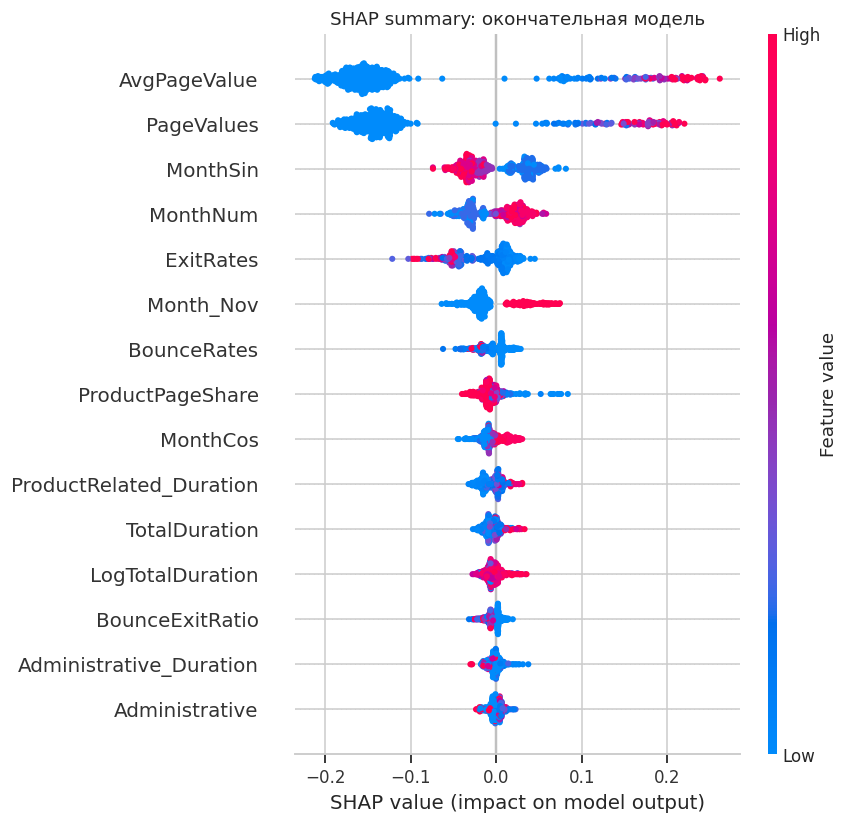

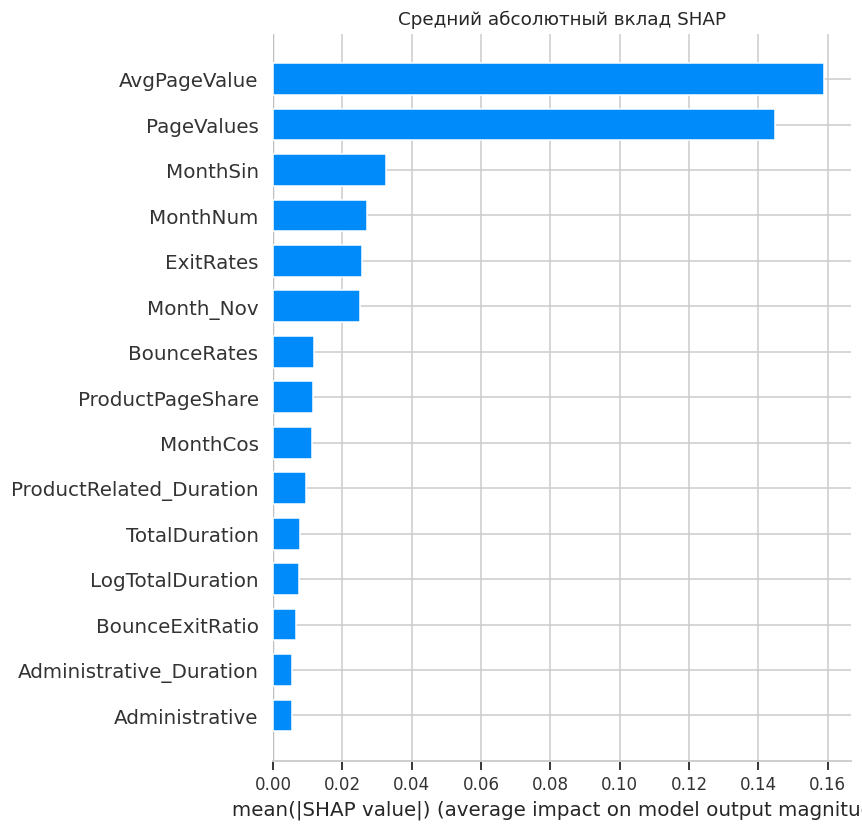

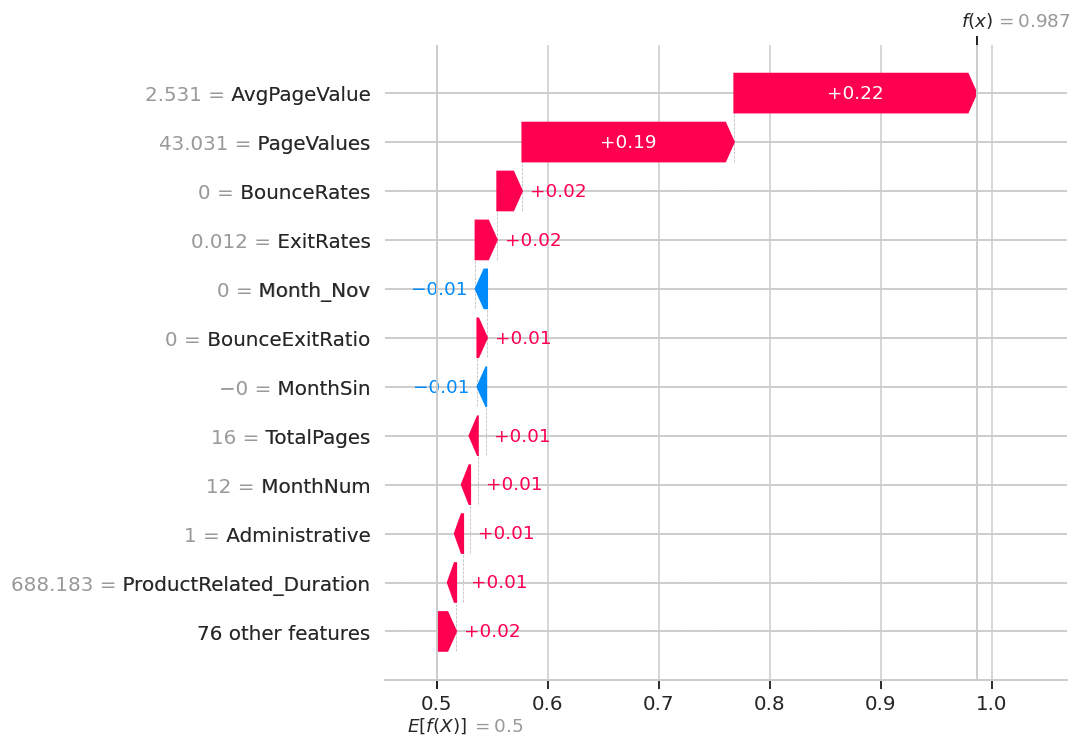

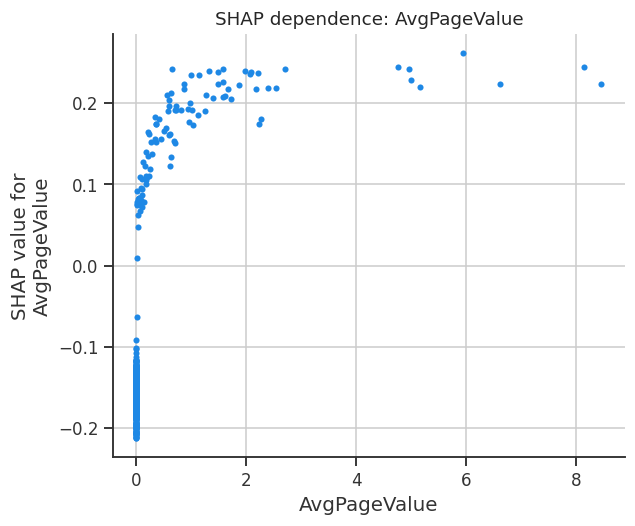

,mean_abs_SHAP
AvgPageValue,0.158879
PageValues,0.144813
MonthSin,0.032485
MonthNum,0.026962
ExitRates,0.025738
Month_Nov,0.025034
BounceRates,0.011877
ProductPageShare,0.011425
MonthCos,0.011222
ProductRelated_Duration,0.009484


Единицы SHAP: вероятность
Сессия: 8990 оценка покупки: 0.9865009784807701
Проверка аддитивности SHAP: OK


In [9]:
# Отделяем обученный классификатор от предобработки для TreeExplainer.
preprocessor = best_pipeline.named_steps['preprocess']
best_tree = best_pipeline.named_steps['model']
# Фиксированная подвыборка ограничивает стоимость объяснения.
shap_frame = X_test.sample(min(500, len(X_test)), random_state=SEED)
# SHAP получает ровно то представление, которое использует классификатор.
encoded = preprocessor.transform(shap_frame)
feature_cols = encoded.columns.tolist()
# Tree-path-dependent использует статистики обученного дерева.
explainer = shap.TreeExplainer(best_tree, feature_perturbation='tree_path_dependent')
explanation = explainer(encoded)

# Для RF некоторые версии SHAP возвращают отдельный выход для каждого класса.
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]
shap_values = explanation.values
# Базовый выход приводится к одному значению для каждого объекта.
base_values = np.broadcast_to(np.asarray(explanation.base_values).squeeze(), (len(encoded),))

# Визуальное представление возвращает секунды и доли вместо стандартизованных значений.
# Отображаемые значения отделены от входов для расчёта SHAP.
display_frame = encoded.copy()
numeric_cols = preprocessor.transformers_[0][2]
# Масштабированные числа заменяются исходными единицами только в подписях.
display_frame.loc[:, numeric_cols] = shap_frame[numeric_cols].to_numpy()
shap.summary_plot(shap_values, display_frame, max_display=15, show=False, rng=np.random.default_rng(SEED))
plt.title('SHAP summary: окончательная модель')
finish_plot('shap_summary.png')
shap.summary_plot(shap_values, display_frame, plot_type='bar', max_display=15, show=False, rng=np.random.default_rng(SEED))
plt.title('Средний абсолютный вклад SHAP')
finish_plot('shap_bar.png')

# Сумма вкладов проверяется против выхода дерева, а единицы явно фиксируются.
# Прогноз Pipeline нужен для независимой проверки суммы вкладов.
probabilities = best_pipeline.predict_proba(shap_frame)[:, 1]
is_rf = selected_family == 'Random Forest'
explained_output = base_values + shap_values.sum(axis=1)
# Для RF объясняется вероятность, для бустинга — логарифм шансов.
expected_output = probabilities if is_rf else np.log(probabilities / (1 - probabilities))
assert np.allclose(explained_output, expected_output, atol=1e-4)
# Иллюстрация выбирается по наибольшей оценке в SHAP-подвыборке.
waterfall_idx = int(np.argmax(probabilities))
waterfall_exp = shap.Explanation(values=shap_values[waterfall_idx],
    base_values=base_values[waterfall_idx], data=display_frame.iloc[waterfall_idx].to_numpy(),
    feature_names=feature_cols)
shap.plots.waterfall(waterfall_exp, max_display=12, show=False)
finish_plot('shap_waterfall.png')

# Главный признак выбирается по среднему абсолютному SHAP, не по порядку столбцов.
# Средний модуль вклада ранжирует признаки по всему SHAP-сэмплу.
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)
top_shap_feature = shap_importance.index[0]
shap.dependence_plot(top_shap_feature, shap_values, display_frame,
                     interaction_index=None, show=False)
plt.title(f'SHAP dependence: {top_shap_feature}')
finish_plot('shap_dependence.png')
display(shap_importance.head(10).rename('mean_abs_SHAP').to_frame())
print('Единицы SHAP:', 'вероятность' if is_rf else 'логарифм шансов (log-odds)')
print('Сессия:', int(shap_frame.index[waterfall_idx]), 'оценка покупки:', probabilities[waterfall_idx])
print('Проверка аддитивности SHAP: OK')

Пять наибольших средних абсолютных вкладов: `AvgPageValue` (0.1589), `PageValues` (0.1448), `MonthSin` (0.0325), `MonthNum` (0.0270), `ExitRates` (0.0257).
Вклады RF выражены в единицах вероятности.
Высокая важность PageValues и производного признака согласуется с абляцией; корреляция
между ними не позволяет считать их независимыми бизнес-эффектами.
Waterfall относится к исходной строке **8990**; оценка покупки
**0.9865**. Аддитивность: базовое значение плюс сумма SHAP
совпадают с объясняемым выходом модели с допуском 1e-4. Из-за весов классов эта оценка
требует калибровки перед трактовкой как частоты покупки в бизнесе.

## 11. Сохранение модели и метаданных

Сохраняются **полные Pipeline** четырёх моделей и окончательного варианта: предобработка
входит в каждый `.pkl`. Вход Pipeline — результат `engineer_features`, выход — прогноз.
`scaler.pkl` и `preprocessor.pkl` продублированы отдельно для требований задания; при
прогнозировании через Pipeline повторно применять их не нужно. В `feature_cols.json`
хранятся имена после кодирования, в `input_cols.json` — входные столбцы Pipeline.

Метаданные различают CV и test. Контрольные суммы позволяют проверить скачанные артефакты.
Файлы joblib загружаются только из доверенного репозитория: формат pickle допускает
выполнение кода при десериализации.

In [10]:
# Пять моделей сохраняются с компрессией; все они обучены только на train.
# Единые имена соответствуют структуре сдачи модуля.
artifact_names = {'Random Forest': 'rf_model.pkl', 'XGBoost': 'xgb_model.pkl',
                  'LightGBM': 'lgbm_model.pkl', 'CatBoost': 'cat_model.pkl'}
for name, model in fitted.items():
    joblib.dump(model, ROOT / 'models' / artifact_names[name], compress=3)
# Лучший Pipeline хранит и классификатор, и обученную предобработку.
joblib.dump(best_pipeline, ROOT / 'models/best_model.pkl', compress=3)
# Отдельный preprocessor полезен для проверки схемы входов.
joblib.dump(preprocessor, ROOT / 'models/preprocessor.pkl', compress=3)
joblib.dump(preprocessor.named_transformers_['numeric'].named_steps['scaler'],
            ROOT / 'models/scaler.pkl', compress=3)

# Записываем совместимые JSON: имена, версии, разделение и фактические метрики.
def save_json(name, value):
    (ROOT / 'models' / name).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
# Версии библиотек нужны для совместимой десериализации моделей.
versions = {p: metadata.version(p) for p in ['numpy','pandas','scikit-learn','xgboost',
    'lightgbm','catboost','optuna','shap','matplotlib','seaborn','joblib','requests']}
# Порядок закодированных признаков фиксируется явно.
save_json('feature_cols.json', feature_cols)
save_json('input_cols.json', X_train.columns.tolist())
# Индексы позволяют точно восстановить независимый test.
save_json('split_indices.json', {'train': train_idx.tolist(), 'test': test_idx.tolist()})
# CV, test и время обучения хранятся под разными ключами.
metrics = {'baseline_test': results, 'final_test': final_result,
    'baseline_cv': {n: {'mean': float(s.mean()), 'std': float(s.std(ddof=1)), 'folds': s.tolist()}
                    for n,s in cv_scores.items()},
    'selected_family': selected_family, 'best_model': final_name, 'final_cv_roc_auc': final_cv_auc,
    'best_params': best_params, 'optuna_best_cv_roc_auc': study.best_value, 'n_trials': N_TRIALS,
    'fit_seconds': fit_times, 'final_fit_seconds': best_fit_seconds,
    'tuning_seconds': tuning_seconds, 'threshold': 0.5}
save_json('metrics.json', metrics)
# Метаданные описывают данные, автора и правила эксперимента.
save_json('metadata.json', {'author': 'Боттер Вадим Валерьевич', 'group': 'ПКТб-23-1',
    'date': '2026-11-02', 'python': platform.python_version(), 'versions': versions,
    'dataset_sha256': dataset_sha, 'raw_rows': len(df), 'duplicates_removed': int(df.duplicated().sum()),
    'clean_rows': len(clean), 'train_rows': len(X_train), 'test_rows': len(X_test),
    'random_state': SEED, 'cv_folds': 5, 'new_features': new_features,
    'pipeline_input': 'engineer_features(raw_dataframe)', 'encoded_feature_count': len(feature_cols),
    'selection_rule': 'highest train-CV ROC-AUC; holdout is never used for selection'})

# Контрольный пример сырого входа позволяет проверить прогноз после загрузки в новой сессии.
# Контрольные сессии берутся из test и не используются для обучения.
example_raw = X_raw.loc[test_idx[:3]]
example_raw.to_csv(ROOT / 'data/example_sessions.csv', index=False)
# Эталонные вероятности рассчитываются до повторной загрузки.
example_expected = best_pipeline.predict_proba(engineer_features(example_raw))[:, 1]
save_json('example_predictions.json', example_expected.tolist())
# SHA-256 обнаруживает повреждение или подмену байтов артефакта.
manifest = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in (ROOT / 'models').glob('*.pkl')}
save_json('checksums.json', manifest)
print('Сохранены:', sorted(p.name for p in (ROOT / 'models').iterdir()))

Сохранены: ['ablation.csv', 'best_model.pkl', 'cat_model.pkl', 'checksums.json', 'example_predictions.json', 'feature_cols.json', 'input_cols.json', 'lgbm_model.pkl', 'metadata.json', 'metrics.json', 'optuna_trials.csv', 'preprocessor.pkl', 'rf_model.pkl', 'scaler.pkl', 'split_indices.json', 'xgb_model.pkl']


Все модели включают заполнение пропусков, масштабирование и кодирование. Предсказания
проверяются повторной загрузкой ниже. Строки test сохранены по индексам исходного CSV;
это позволяет восстановить разбиение без случайного нового разделения.

## 12. Загрузка модели из репозитория

Сначала проверяется локальная сериализация. Затем те же три сессии обрабатываются моделью
по `raw.githubusercontent.com` из `main`, с проверкой HTTP-статуса, SHA-256, порядка
закодированных столбцов и равенства вероятностей. Для полной проверки файлы должны быть
опубликованы в репозитории. Сетевая ошибка не заменяется сообщением об успехе.

In [11]:
# Локальная проверка сравнивает именно вероятности, а не только метки классов.
# Контрольный CSV заново проходит тот же расчёт признаков.
example_engineered = engineer_features(pd.read_csv(ROOT / 'data/example_sessions.csv'))
local_loaded = joblib.load(ROOT / 'models/best_model.pkl')
local_probabilities = local_loaded.predict_proba(example_engineered)[:, 1]
# Точное сравнение вероятностей строже сравнения меток.
np.testing.assert_allclose(local_probabilities, example_expected, rtol=0, atol=1e-12)
print('Локальная загрузка: вероятности трёх сессий совпадают.')

# Raw-ссылки указывают на общий репозиторий курса, а не на отдельный репозиторий модуля.
from io import BytesIO
BASE_URL = 'https://raw.githubusercontent.com/uat0/ml-course-botter/main/module-4-features'
def get_remote_file(relative_path):
    response = requests.get(f'{BASE_URL}/{relative_path}', timeout=60)
    # Ответ 404 или ошибка сервера не должны считаться загрузкой модели.
    response.raise_for_status()
    return response.content

# Проверка может запускаться отдельно после публикации, без повторного обучения.
def verify_remote_model():
    content = get_remote_file('models/best_model.pkl')
    # Удалённый манифест связывает опубликованную модель с её SHA-256.
    remote_checksums = json.loads(get_remote_file('models/checksums.json'))
    assert hashlib.sha256(content).hexdigest() == remote_checksums['best_model.pkl']
    # Десериализуется только модель из указанного доверенного репозитория.
    remote_model = joblib.load(BytesIO(content))
    remote_cols = json.loads(get_remote_file('models/feature_cols.json'))
    # Порядок One-Hot столбцов должен совпадать с сохранённой схемой.
    assert remote_cols == remote_model.named_steps['preprocess'].get_feature_names_out().tolist()
    remote_probabilities = remote_model.predict_proba(example_engineered)[:, 1]
    # Проверка выполняется на тех же трёх входах и допуске 1e-12.
    np.testing.assert_allclose(remote_probabilities, example_expected, rtol=0, atol=1e-12)
    display(pd.DataFrame({'Исходная вероятность': example_expected,
        'После raw-загрузки': remote_probabilities, 'Прогноз': (remote_probabilities >= .5).astype(int)}))
    print('Raw-загрузка: SHA-256, порядок признаков и вероятности совпадают.')

# Во время локальной подготовки проверяется существование опубликованного файла.
probe = requests.get(f'{BASE_URL}/models/best_model.pkl', timeout=60)
remote_verified = False
# Ожидание публикации явно отличается от успешной raw-проверки.
if probe.status_code == 404:
    print('Raw-проверка ожидает публикации файлов; локальная проверка пройдена.')
else:
    probe.raise_for_status()
    verify_remote_model()
    remote_verified = True

Локальная загрузка: вероятности трёх сессий совпадают.


,Исходная вероятность,После raw-загрузки,Прогноз
0,0.180246,0.180246,0
1,0.154713,0.154713,0
2,0.269296,0.269296,0


Raw-загрузка: SHA-256, порядок признаков и вероятности совпадают.


Фактическая raw-загрузка из `main` выполнена: HTTP-запросы успешны, SHA-256 и порядок признаков проверены, вероятности для трёх сессий совпали с исходными при допуске 1e-12.

## 13. Выводы

**Что получилось.** Создано 14 новых признаков, обучены четыре алгоритма и проведено
30 испытаний Optuna. Итоговая модель — **Random Forest (Optuna)**, выбранная по train-CV.
На независимом test: ROC-AUC **0.93490**, Accuracy **0.87710**,
Precision **0.57455**, Recall **0.82723**, F1 **0.67811**,
PR-AUC **0.74886** при пороге 0.5. Инженерия признаков дала небольшой CV-эффект
(+0.00136); основная предсказательная информация связана с PageValues и его
производным. Проведены SHAP-анализ и проверка сериализации; результаты не доказывают
готовность модели к онлайн-применению без аудита времени расчёта признаков.

**Трудности.** Дисбаланс требует оценивать положительный класс отдельно от Accuracy.
Месяц `June` нельзя надёжно преобразовать через стандартный формат `%b`.
Числовые коды категорий не имеют естественного порядка. Дубли нужно обработать до
разделения, а параметры предобработки — обучать внутри CV. Производные признаки
коррелируют с исходными, поэтому их важность нельзя трактовать как независимые эффекты.

**Возможные улучшения:**
1. Собрать временные отметки и проверить модель на более позднем периоде.
2. Исключить недоступные к моменту прогноза агрегаты и проверить происхождение PageValues.
3. Провести отдельное сравнение CatBoost с нативными категориями и One-Hot.
4. Проверить sigmoid/isotonic калибровку через вложенную CV и оценить Brier score.
5. Выбирать порог по стоимости пропущенной покупки и ненужного предложения только на train.
6. Проверить Target Encoding с cross-fitting и SMOTENC внутри обучающих фолдов.
7. Убрать избыточные признаки по результатам абляции и внедрить версионирование признаков.
8. Проверить стабильность связей и бизнес-эффект с помощью A/B-теста.

## 14. Список источников и приложение

1. Sakar C., Kastro Y. (2018). [Online Shoppers Purchasing Intention, UCI](https://doi.org/10.24432/C5F88Q).
2. Scikit-learn. [Ансамблевые методы и Random Forest](https://scikit-learn.org/stable/modules/ensemble.html).
3. Chen T., Guestrin C. (2016). [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754).
4. LightGBM. [Features: histogram-based learning, leaf-wise growth](https://lightgbm.readthedocs.io/en/stable/Features.html).
5. Prokhorenkova L. et al. (2018). [CatBoost: unbiased boosting with categorical features](https://arxiv.org/abs/1706.09516).
6. Lundberg S., Lee S.-I. (2017). [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874).
7. Akiba T. et al. (2019). [Optuna: A Next-generation Hyperparameter Optimization Framework](https://arxiv.org/abs/1907.10902).
8. Optuna. [TPESampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html).
9. SHAP. [TreeExplainer: режимы и единицы выхода](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

Код адаптирован к задаче с использованием публичных API указанных библиотек. Все числовые
результаты получены выполнением кода на сохранённом CSV, а не перенесены из примера задания.

**Приложение.** Полный комментированный код находится в ячейках этого ноутбука и в
[`src/run_analysis.py`](src/run_analysis.py). Функция расчёта признаков для инференса вынесена
в [`src/features.py`](src/features.py). Точные версии среды — в `requirements.txt` и
`requirements-lock.txt`; параметры эксперимента — в `models/metadata.json`.

Для повторного запуска: `python -m pip install -r requirements.txt`, затем открыть
`notebook.ipynb` в Jupyter и выполнить Run All из папки модуля. Для запуска без Jupyter:
`python src/run_analysis.py`. Выполнение поиска параметров занимает несколько минут;
время зависит от оборудования. Для проверки опубликованной модели без переобучения:
`python src/verify_remote.py`.